# Session 11 — Attention

Read this sentence: *The robot put the battery in the device because **it** was empty.* What does "it" refer to? A person says "the battery" at once. To work that out, a model has to look back at earlier words and weigh them. An LSTM (Session 10) has to carry everything it might need through one running memory. **Attention** gives each word a direct way to look at every other word and decide how much each one matters. It is the core of the **transformer**, the architecture introduced in 2017 in the paper "Attention Is All You Need", on which BERT, the model used here, and the language models of Session 12 are built.

This session computes attention by hand on a small designed example, adds the mask used when generating text, and then looks at what real attention in a trained model does with the same sentence.

**By the end of the session you should be able to:**

1. describe attention as each token asking a question (a query) and collecting information from the tokens whose keys match it;
2. explain the causal mask that stops a text generator reading ahead;
3. read real attention weights from BERT and say what they do and don't show, and explain why it cuts text into subwords.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `torch` and `transformers`. The first run downloads BERT (about 440 MB). The outputs are already saved in the notebook. It runs in under a minute on a laptop, and your BERT numbers may differ slightly from the ones quoted in the text.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

tokens = ["robot", "battery", "because", "it", "empty"]
# Each token has three features: robot-like, battery-like, pronoun.
X = np.array([[1.0, 0.0, 0.0],
              [0.0, 1.0, 0.0],
              [0.0, 0.0, 0.2],
              [0.0, 0.2, 1.0],
              [0.0, 0.6, 0.2]])
W_q = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 4.0, 0.0]])  # a pronoun asks for "something battery-like"
W_k = np.eye(3)
W_v = np.array([[1.0, 0.0], [0.0, 1.0], [0.5, 0.5]])

Q, K, V = X @ W_q, X @ W_k, X @ W_v
scores = Q @ K.T / np.sqrt(K.shape[1])


def softmax(s):
    e = np.exp(s - s.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


weights = softmax(scores)
pd.DataFrame(weights, index=tokens, columns=tokens).round(2)

,robot,battery,because,it,empty
robot,0.31,0.17,0.17,0.17,0.17
battery,0.16,0.28,0.16,0.18,0.22
because,0.17,0.26,0.17,0.18,0.22
it,0.05,0.59,0.05,0.08,0.22
empty,0.14,0.32,0.14,0.17,0.23


## 1. Attention by hand

Five tokens from the sentence: *robot, battery, because, it, empty*. We give each token three made-up features (robot-like, battery-like, pronoun), and set the weights so that a pronoun looks for something battery-like. The numbers are chosen by us so the example is easy to read. In a real model they are learned.

Each token is turned into three vectors:

- a **query** $q$: what this token is looking for;
- a **key** $k$: what this token offers to be found by;
- a **value** $v$: the information it hands over when it is chosen.

The score between token $i$ and token $j$ is the dot product $q_i\cdot k_j$, divided by $\sqrt{d_k}$ (the number of key features) to keep scores in a sensible range. A softmax turns each row of scores into weights that add up to 1. The table shows the weights.

> **Pause:** which token should "it" pay most attention to? Look at the "it" row.

The "it" row gives 0.59 to *battery*, 0.22 to *empty*, 0.08 to itself, and 0.05 each to *robot* and *because*. The other rows are close to even, because we only gave the pronoun a special query.

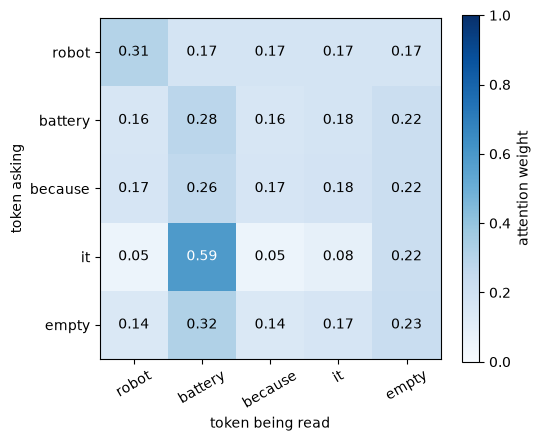

Value vectors (what each token offers):
          v1   v2
robot    1.0  0.0
battery  0.0  1.0
because  0.1  0.1
it       0.5  0.7
empty    0.1  0.7

New vector for 'it' = weighted mix of those: [0.12 0.81]  (its own value was [0.5 0.7] )


In [2]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(weights, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(tokens)), tokens, rotation=30)
ax.set_yticks(range(len(tokens)), tokens)
ax.set(xlabel="token being read", ylabel="token asking")
for i in range(len(tokens)):
    for j in range(len(tokens)):
        ax.text(j, i, f"{weights[i, j]:.2f}", ha="center", va="center", color="white" if weights[i, j] > 0.5 else "black")
plt.colorbar(image, label="attention weight")
plt.show()

context = weights @ V
print("Value vectors (what each token offers):")
print(pd.DataFrame(V, index=tokens, columns=["v1", "v2"]).round(2).to_string())
print("\nNew vector for 'it' = weighted mix of those:", context[tokens.index("it")].round(2), " (its own value was", V[tokens.index("it")].round(2), ")")

The picture shows the same table as a heatmap. The dark cell is the "it" → "battery" weight.

Each token's new vector is the weighted mix of all the value vectors. For "it", that is 0.12 on the first feature and 0.81 on the second: it has moved from its own value (0.5, 0.7) towards the battery's value (0, 1). After this step the vector for "it" carries information about the battery. Stacking such layers is how a transformer builds each word's meaning from its context.

In [3]:
mask = np.tril(np.ones((len(tokens), len(tokens)), dtype=bool))
causal_weights = softmax(np.where(mask, scores, -1e9))
pd.DataFrame(causal_weights, index=tokens, columns=tokens).round(2)

,robot,battery,because,it,empty
robot,1.00,0.00,0.00,0.00,0.00
battery,0.36,0.64,0.00,0.00,0.00
because,0.28,0.44,0.28,0.00,0.00
it,0.07,0.76,0.07,0.11,0.00
empty,0.14,0.32,0.14,0.17,0.23


## 2. The causal mask

A model that generates text predicts the next word, so it must not read the words after the current one. The **causal mask** sets every score to a huge negative number where the column is later than the row, so the softmax gives those positions weight zero.

In the table, *robot* attends only to itself (1.00), *battery* to robot and itself (0.36 and 0.64), and "it" to the four tokens up to and including "it" (0.07, 0.76, 0.07, 0.11), with the last column (*empty*) at 0.00. The "it" row now puts even more weight on battery (0.76), because *empty* is no longer there to share it. The final row, for *empty*, is the same as before, since it already sees every token.

An encoder model such as BERT reads in both directions and uses no mask. A text generator such as the one in Session 12 uses this mask.

> **Pause:** BERT, next, has 144 attention heads. We give it the sentence twice, once ending in "empty" (so "it" is the battery) and once in "broken" (so "it" is more likely the device). Will one head point from "it" to the right object in both sentences?

In [4]:
import torch
from transformers import AutoTokenizer, AutoModel
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased", output_attentions=True).eval()


def attention_for(sentence):
    encoded = tokenizer(sentence, return_tensors="pt")
    with torch.no_grad():
        attention = torch.stack(bert(**encoded).attentions)[:, 0]  # (layers, heads, tokens, tokens)
    return tokenizer.convert_ids_to_tokens(encoded.input_ids[0]), attention.numpy()


sentences = {"empty": "The robot put the battery in the device because it was empty.", "broken": "The robot put the battery in the device because it was broken."}
results = {name: attention_for(s) for name, s in sentences.items()}
print("BERT:", sum(p.numel() for p in bert.parameters()) // 1_000_000, "million parameters,", bert.config.num_hidden_layers, "layers x", bert.config.num_attention_heads, "heads =", bert.config.num_hidden_layers * bert.config.num_attention_heads, "attention maps per sentence")
print("Tokens:", results["empty"][0])

rows = []
for name, (toks, attention) in results.items():
    it = toks.index("it")
    for candidate in ["robot", "battery", "device"]:
        a = attention[:, :, it, toks.index(candidate)]
        layer, head = np.unravel_index(a.argmax(), a.shape)
        rows.append({"sentence ends": name, "'it' looks at": candidate, "average over all heads": round(a.mean(), 3), "strongest head": f"layer {layer + 1}, head {head + 1}", "its weight": round(a.max(), 2)})
pd.DataFrame(rows)

BERT: 109 million parameters, 12 layers x 12 heads = 144 attention maps per sentence
Tokens: ['[CLS]', 'the', 'robot', 'put', 'the', 'battery', 'in', 'the', 'device', 'because', 'it', 'was', 'empty', '.', '[SEP]']


,sentence ends,'it' looks at,average over all heads,strongest head,its weight
0,empty,robot,0.036,"layer 4, head 11",0.58
1,empty,battery,0.037,"layer 5, head 4",0.33
2,empty,device,0.040,"layer 5, head 11",0.41
3,broken,robot,0.039,"layer 4, head 11",0.66
4,broken,battery,0.048,"layer 11, head 7",0.50
5,broken,device,0.038,"layer 5, head 11",0.38


## 3. What a trained model actually does

Our toy was built so that "it" would find "battery". Does a trained transformer do this? BERT (Jacob Devlin and colleagues at Google, 2018) is a transformer trained on large amounts of text to fill in hidden words. It has 109 million parameters, 12 layers, and 12 attention heads in each layer (a head is one independent set of queries, keys and values), so 144 attention maps for every sentence. We give it our sentence twice, ending in "empty" and in "broken", and look at how much "it" attends to *robot*, *battery* and *device*.

The table summarises it. Averaged over all 144 heads, "it" gives each of the three candidates only about 0.04 (an even spread over the 15 tokens would be 0.067). Single heads do much more. The strongest head for *robot* is layer 4, head 11, with weight 0.58 in the "empty" sentence and 0.66 in the "broken" sentence. For *battery*, the strongest head is layer 5, head 4 (0.33) in the "empty" sentence and layer 11, head 7 (0.50) in the "broken" sentence. For *device*, layer 5, head 11 (0.41 and 0.38).

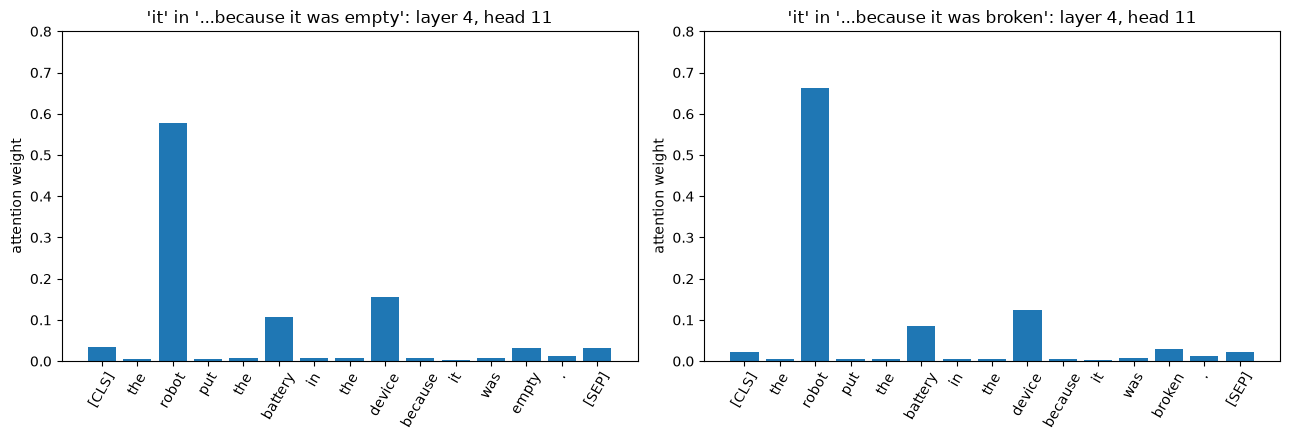

layer 4, head 11, '...was empty': {'robot': 0.58, 'battery': 0.11, 'device': 0.16}
layer 4, head 11, '...was broken': {'robot': 0.66, 'battery': 0.09, 'device': 0.12}


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, (toks, attention)) in zip(axes, results.items()):
    it = toks.index("it")
    ax.bar(range(len(toks)), attention[3, 10, it])
    ax.set_xticks(range(len(toks)), toks, rotation=60)
    ax.set(ylim=(0, 0.8), title=f"'it' in '...because it was {name}': layer 4, head 11", ylabel="attention weight")
plt.tight_layout()
plt.show()
for name, (toks, attention) in results.items():
    print(f"layer 4, head 11, '...was {name}':", {w: round(float(attention[3, 10, toks.index('it'), toks.index(w)]), 2) for w in ['robot', 'battery', 'device']})

The bars show the head that attends most to *robot*, layer 4, head 11, for both sentences. It gives *robot* 0.58 and 0.66, *device* 0.16 and 0.12, and *battery* 0.11 and 0.09. The pattern is almost identical whether the sentence ends in "empty" or "broken", so this head isn't deciding what "it" means from the end of the sentence. What it does appears to be a simpler job, such as pointing at the subject.

We chose this head by searching all 144 for the highest weight, which is picking a best case, and even so it doesn't point at the answer a person would give (the battery). Another head points at the battery, but only in one of the two sentences and only after we looked for it.

The lesson: attention weights show where one layer reads from. They are not an explanation of the model's answer. Meaning is built up over many heads and layers, and the final prediction also depends on the values, the feed-forward layers and the output. Treat a heatmap as a clue to inspect.

In [6]:
for text in ["battery", "unbelievably", "tokenization", "Zorblatt-9000"]:
    print(f"{text:14s} -> {tokenizer.tokenize(text)}")
print(f"\nBERT's vocabulary: {tokenizer.vocab_size:,} pieces. Token ids for 'tokenization': {tokenizer('tokenization', add_special_tokens=False)['input_ids']}")

battery        -> ['battery']
unbelievably   -> ['un', '##bel', '##ie', '##va', '##bly']
tokenization   -> ['token', '##ization']
Zorblatt-9000  -> ['z', '##or', '##bla', '##tt', '-', '900', '##0']

BERT's vocabulary: 30,522 pieces. Token ids for 'tokenization': [19204, 3989]


## 4. Tokens are not always words

The token list printed with the BERT table also contained `[CLS]` and `[SEP]`, markers that BERT adds at the start and end of every input. The words themselves were whole tokens, because they are common. Rarer words are cut into **subwords**, pieces from a fixed vocabulary of 30,522; a piece that continues a word starts with `##`:

- "battery" is one token;
- "tokenization" becomes `token` + `##ization`, ids 19204 and 3989, which is what the model actually receives;
- "unbelievably" becomes five pieces, `un`, `##bel`, `##ie`, `##va`, `##bly`: the pieces are chosen by how often they occur in the training text, not by grammar;
- an invented product name, "Zorblatt-9000", still gets tokens: `z`, `##or`, `##bla`, `##tt`, `-`, `900`, `##0`.

Compare Session 10's word vocabulary, where every word outside the 20,000 most common became the same "other word" id and lost its meaning. With subwords nothing is unknown: any text can be written with the pieces, and related words share pieces. The vocabulary stays a manageable size. That is why transformers, including the language models of Session 12, use them.

## What to take away

- Every token makes a query, a key and a value. Weights come from query–key matches, and the output is a weighted mix of values.
- Attention gives each token a direct route to every other token, whatever the distance.
- A causal mask stops a generator from reading ahead; an encoder doesn't need one.
- In a real model, individual heads do not neatly resolve "it". Be careful when reading heatmaps as explanations.
- Transformers read subword tokens: common words are one token, rare words several pieces, so no word is ever unknown.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## The equations

With token representations stacked in a matrix $X$, learned weights produce $Q=XW_Q$, $K=XW_K$ and $V=XW_V$. Attention is

$$
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V .
$$

Dividing by $\sqrt{d_k}$ stops the dot products growing with the key size, which would push the softmax to put all its weight on one token and make the gradients tiny. With the causal mask the scores for later positions are replaced by $-\infty$ before the softmax.

## Position

Attention alone ignores order: shuffle the tokens and each token gets the same mix, only reordered. Transformers therefore add information about each token's position to its vector, using fixed sine and cosine patterns or learned position vectors.

## Multiple heads

One head can follow one kind of relation. Multi-head attention runs $H$ heads in parallel, each with its own $W_Q^{(h)},W_K^{(h)},W_V^{(h)}$, and joins their outputs with a final matrix $W_O$:

$$
\operatorname{MHA}=\operatorname{Concat}(\operatorname{head}_1,\dots,\operatorname{head}_H)\,W_O .
$$

## The rest of a block

A transformer block has attention, a residual connection and normalisation, then a small feed-forward network applied to each position, with another residual connection and normalisation. Residual connections let information and gradients pass through deep stacks: $x_{\text{out}}=x+\operatorname{Sublayer}(x)$.

## Three layouts

*Encoder* models (BERT) let every token see every other, and suit classification and search. *Decoder* models (the language models of Session 12) use the causal mask and generate text one token at a time. *Encoder–decoder* models read a source with an encoder and write the output with a decoder, as in translation.

## Costs

Every token attends to every other, so compute and memory grow with the square of the text length, and a model has a fixed context window.